# Multi-location energy planning for Houston, San Diego, and New York

Decide where to build generating and electrolysis capacity, and route energy from the two production sites to New York. The legacy rail-only case delivers hydrogen to a fuel cell in New York. A second solve adds a grid option to compare hydrogen rail with direct power transmission.

## Location and link inputs

The profiles use four six-hour blocks in UTC. Solar availability is derived from the legacy NSRDB series for Houston and San Diego on July 15, 2019. The New York demand shape comes from July 15, 2018, the load year included in the legacy case. The demand is scaled to a 35 MW peak. Routes use the legacy distances of 2,366 and 2,620 miles and explicit delivery efficiencies of 97% for hydrogen and 99.9% for electricity. Costs are illustrative.

This is a representative-day teaching example, with different technologies and costs from the 8,760-hour legacy study. Its objective is not an annual parity result. The source study’s implemented rail balance was lossless despite its `trans_loss=0.03` input. Here, losses are modeled explicitly and checked below.


In [1]:
from math import isclose

import pandas as pd
from energia import Location, Model, Periods, Process, Resource, Transport
from gana import inf

pv_profile = {'houston': [0.0079, 0.0, 0.1141, 0.1402], 'san_diego': [0.154, 0.0, 0.4087, 0.935]}
demand = [33.75, 27.67, 30.85, 35.0]
distances = {"houston": 2366, "san_diego": 2620}
block_hours = 6

## Make the spatial formulation

Hydrogen and power have separate mass balances. The rail service ships tonnes of hydrogen and the grid service ships electricity. A fuel cell produces electricity from rail deliveries after the link losses.

In [2]:
def plan_network(enable_grid):
    m = Model("rail_and_grid" if enable_grid else "rail_only")
    m.block = Periods()
    m.day = len(demand) * m.block
    m.declare(Location, ["houston", "san_diego", "new_york"])
    m.declare(Resource, ["sun", "gas", "power", "hydrogen", "vented_hydrogen", "lost_power"])
    for site in (m.houston, m.san_diego, m.new_york):
        _ = m.power.consume(site, m.block) == 0
        _ = m.hydrogen.consume(site, m.block) == 0
    served = m.power.release(m.new_york, m.block)
    _ = served == demand
    cost = 0

    for site_name, miles in distances.items():
        site = getattr(m, site_name)
        _ = m.sun.consume(site, m.block) >= 0
        _ = m.gas.consume(site, m.block) >= 0
        plants = (
            ("pv", m.power == -m.sun, pv_profile[site_name], 85 if site_name == "houston" else 72, 0),
            ("gas", m.power == -0.108 * m.gas, 1, 80, 55 if site_name == "houston" else 70),
            ("electrolysis", m.hydrogen == -52 * m.power, 1, 100, 0),
        )
        for name, conversion, availability, capex, opex in plants:
            plant = Process(conversion)
            setattr(m, f"{site_name}_{name}", plant)
            capacity = plant.capacity(site, m.day)
            dispatch = plant.operate(site, m.block)
            _ = capacity <= 200
            _ = dispatch <= availability
            plant.locate(site)
            cost += capex * capacity.V()[0]
            if opex:
                cost += block_hours * opex * sum(dispatch.V())
        m.Link(site, m.new_york, dist=miles)

    m.fuel_cell = Process(m.power == -0.05 * m.hydrogen)
    cell_capacity = m.fuel_cell.capacity(m.new_york, m.day)
    _ = cell_capacity <= 40
    _ = m.fuel_cell.operate(m.new_york, m.block) <= 1
    m.fuel_cell.locate(m.new_york)
    cost += 120 * cell_capacity.V()[0]

    m.rail = Transport()
    # Transport's coefficient scales both ends; it is not a loss fraction.
    _ = m.rail(m.hydrogen) == 1
    if enable_grid:
        m.grid = Transport()
        _ = m.grid(m.power) == 1

    shipments = {}
    for site_name, miles in distances.items():
        link = getattr(m, site_name) - m.new_york
        services = [(m.rail, 10, 0.001667)]
        if enable_grid:
            services.append((m.grid, 16, 0.0005))
        for service, limit, rate in services:
            _ = service.capacity(link, m.day) == limit
            dispatch = service.operate(link, m.block)
            _ = dispatch <= 1
            service.locate(link)
            cost += block_hours * miles * rate * sum(dispatch.V())
            shipments[f"{site_name} {service.name}"] = dispatch

    # Remove losses at the destination with explicit resource balances.
    loss_samples = {}
    for service_name, resource, waste, efficiency in (
        ("rail", m.hydrogen, m.vented_hydrogen, 0.97),
        ("grid", m.power, m.lost_power, 0.999),
    ):
        if service_name == "grid" and not enable_grid:
            continue
        loss = Process(waste == -resource)
        setattr(m, f"{service_name}_loss", loss)
        _ = waste.release(m.new_york, m.block) >= 0
        lost = loss.operate(m.new_york, m.block)
        incoming = [list(shipments[f"{site} {service_name}"].V()) for site in distances]
        for t, amount in enumerate(lost.V()):
            setattr(m.program, f"{service_name}_loss_{t}",
                    amount == (1 - efficiency) * sum(flow[t] for flow in incoming))
        loss.locate(m.new_york)
        loss_samples[service_name] = lost

    m.program.delivered_cost = inf(cost)
    m.opt()
    assert all(isclose(a, b, abs_tol=1e-6) for a, b in zip(served.output(aslist=True), demand, strict=True))
    flows = {name: block_hours * sum(sample.output(aslist=True)) for name, sample in shipments.items()}
    rail_flows = [shipments[f"{site} rail"].output(aslist=True) for site in distances]
    cell = m.fuel_cell.operate(m.new_york, m.block).output(aslist=True)
    rail_losses = loss_samples["rail"].output(aslist=True)
    grid_flows = ([shipments[f"{site} grid"].output(aslist=True) for site in distances]
                  if enable_grid else [[0] * len(demand)])
    grid_losses = loss_samples["grid"].output(aslist=True) if enable_grid else [0] * len(demand)
    for t, load in enumerate(demand):
        hydrogen_sent = sum(flow[t] for flow in rail_flows)
        power_sent = sum(flow[t] for flow in grid_flows)
        assert isclose(rail_losses[t], 0.03 * hydrogen_sent, abs_tol=1e-7)
        assert isclose(0.97 * hydrogen_sent, 0.05 * cell[t], abs_tol=1e-7)
        assert isclose(grid_losses[t], 0.001 * power_sent, abs_tol=1e-7)
        assert isclose(cell[t] + 0.999 * power_sent, load, abs_tol=1e-7)
    return {"Daily cost": m.program.active_objective.X,
            "Hydrogen lost (tonnes)": block_hours * sum(rail_losses),
            "Grid losses (MWh)": block_hours * sum(grid_losses), **flows}

## Compare transport options

Rail shipments are in tonnes of hydrogen. Grid flows are in MWh. The option to use direct transmission can reduce cost because the model may still use rail whenever it is cheaper or needed to meet demand.

In [3]:
rail = plan_network(enable_grid=False)
combined = plan_network(enable_grid=True)
assert rail["Daily cost"] >= combined["Daily cost"] - 1e-6
assert rail["houston rail"] + rail["san_diego rail"] > 0
assert combined["houston grid"] + combined["san_diego grid"] > 0
assert isclose(rail["houston rail"] + rail["san_diego rail"],
               block_hours * sum(demand) * 0.05 / 0.97, abs_tol=1e-6)
pd.DataFrame([rail, combined], index=["Rail only", "Rail and grid"]).fillna(0).round(2)

,Daily cost,Hydrogen lost (tonnes),Grid losses (MWh),houston rail,san_diego rail,houston grid,san_diego grid
Rail only,69499.68,1.18,0.00,15.55,23.81,0.00,0.00
Rail and grid,30615.83,0.33,0.55,0.00,10.95,193.59,358.19


## Full-year parity reference

The [original hourly study](https://github.com/cacodcar/kuru/blob/db35908bd9056ef8f484c425bf2d2cb428677a83/studies/examples_old/multiperiod/ml-sp-milp.ipynb) uses 8,760 hours, an 80 MW New York peak, the original technology and storage sets, and lossless rail in its implemented balances. Its saved Gurobi results are:

| Objective | Archived result |
|---|---:|
| Minimum annual cost | 1,847,843,268.177 |
| Maximum annual New York electricity delivery | 3,202,802,043.034 MWh |

The [full-year audit](https://github.com/TAMUparametric/energiapy/tree/main/tools/multilocation_parity) now includes the original inputs, source pins, model code and recorded results. It compares the full Energia matrix against independent balance equations and the archived objectives, with a 0.001 absolute objective tolerance. All hours, annual capacities and chronological inventory links are retained. From a repository checkout, run:

```bash
python -m pip install -e . -r tools/multilocation_parity/requirements.txt
python -m tools.multilocation_parity /tmp/multilocation-full
```

This separate annual audit preserves the implemented lossless rail convention. The representative-day results above include explicit losses and must not be compared numerically with the annual objectives. The PR workflow executes a 48-hour regression; a manual full-year workflow runs the annual audit.


## Shipments by origin and transport mode

Compare sending-end daily shipments, before transport losses. Rail carries
hydrogen in tonnes per day; the grid carries electricity in MWh per day.
Keep them in separate panels and preserve each origin's pattern across
panels. Grid shipments are zero in the rail-only scenario because that
option is disabled. The result dictionaries already include block duration.

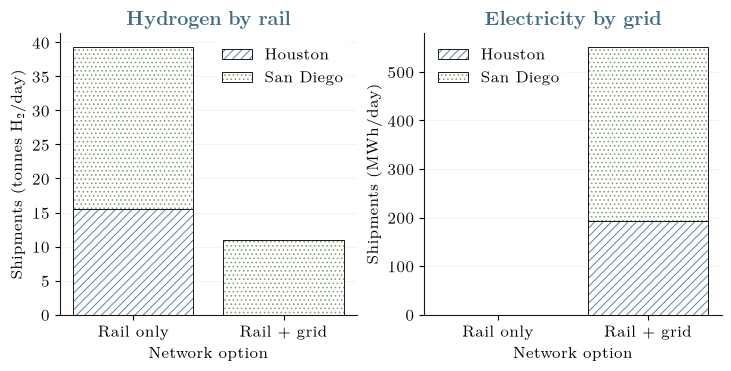

In [4]:
from gana.plotting import Series, row, stacked

scenarios = pd.DataFrame([rail, combined]).fillna(0)
shipment_plots = []
for mode, title, unit in [
    ("rail", "Hydrogen by rail", r"tonnes H$_2$/day"),
    ("grid", "Electricity by grid", "MWh/day"),
]:
    origins = [
        Series(
            x=(0, 1),
            values=tuple(scenarios[f"{site} {mode}"]),
            coordinates=(0, 1),
            domain=("network option",),
            key=(site,),
            label=site.replace("_", " ").title(),
            unit=unit,
        )
        for site in distances
    ]
    shipment_plots.append(
        stacked(
            *origins,
            title=title,
            ylabel=f"Shipments ({unit})",
            ticks=[0, 1],
            tick_labels=["Rail only", "Rail + grid"],
        )
    )
shipment_plot = row(
    *shipment_plots,
    sharex=True,
    fig_size=(7.2, 3.6),
    xlabel="Network option",
    ylim=(0, None),
)
shipment_plot.show();